In [ ]:
# Shared project paths: works when opened from the repository root or task7/notebooks.
import os
from pathlib import Path


def _find_task7_root():
    cwd = Path.cwd().resolve()
    candidates = []
    for parent in (cwd, *cwd.parents):
        candidates.extend((parent, parent / "task7"))
    for folder in candidates:
        if (folder / "results" / "task7" / "task7_split_manifest.csv").is_file():
            return folder
    raise FileNotFoundError(
        "Cannot locate task7/results/task7/task7_split_manifest.csv. "
        "Open this notebook from the extracted task7 folder or its parent repository."
    )


MODULE_ROOT = _find_task7_root()


def resolve_dataset_path(manifest_path):
    """Resolve manifest paths against the supplied dataset, not the notebook cwd."""
    path = Path(manifest_path)
    if path.is_absolute():
        if path.is_file():
            return path
        raise FileNotFoundError(path)
    # Manifest paths start with dataset_2026/<class>/<filename>.
    relative = Path(*path.parts[1:]) if path.parts and path.parts[0].lower() == "dataset_2026" else path
    explicit = os.environ.get("ME5411_DATASET_DIR", "")
    roots = ([Path(explicit)] if explicit else []) + [
        MODULE_ROOT.parent / "dataset_2026",
        MODULE_ROOT / "dataset_2026",
    ]
    for root in roots:
        candidate = root / relative
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Missing dataset image: {manifest_path}. Place dataset_2026 next to "
        "task7/, or set ME5411_DATASET_DIR to its location."
    )

print("Task 7 directory:", MODULE_ROOT)


## Task 7 — CNN classification

Small two-convolution-layer network trained from scratch. All results are from the original Windows CPU experiment. The frozen test split is used only after model selection.

In [1]:
%matplotlib inline

## 1. Environment and data manifest

Run this notebook in the CNN environment; the README documents its separate dependencies and CPU installation.

In [2]:


import sys

print("Python version:", sys.version.split()[0])

try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("PyTorch is ready!")

except ImportError:
    print("PyTorch is not installed.")


Python version: 3.11.18
PyTorch version: 2.15.0+cpu
CUDA available: False
PyTorch is ready!


In [3]:

import csv
from pathlib import Path
from collections import Counter
import numpy as np
import cv2
import matplotlib.pyplot as plt

manifest_path = MODULE_ROOT / "results/task7/task7_split_manifest.csv"

assert manifest_path.is_file(), "CSV file not found!"

with open(manifest_path, "r", encoding="utf-8") as f:
    dataset_records = list(csv.DictReader(f))

class_names = ["0", "4", "7", "8", "A", "D", "H"]

label_to_index = {
    label: i
    for i, label in enumerate(class_names)
}

train_records = [
    r for r in dataset_records
    if r["split"] == "train"
]

val_records = [
    r for r in dataset_records
    if r["split"] == "val"
]

test_records = [
    r for r in dataset_records
    if r["split"] == "test"
]

print("Training samples:", len(train_records))
print("Validation samples:", len(val_records))
print("Test samples:", len(test_records))

print("Character classes:", class_names)
print("Label mapping:", label_to_index)

assert len(train_records) == 4536
assert len(val_records) == 798
assert len(test_records) == 1778

print("Dataset split loaded successfully!")


Training samples: 4536
Validation samples: 798
Test samples: 1778
Character classes: ['0', '4', '7', '8', 'A', 'D', 'H']
Label mapping: {'0': 0, '4': 1, '7': 2, '8': 3, 'A': 4, 'D': 5, 'H': 6}
Dataset split loaded successfully!


## 2. Preprocessing and DataLoader

Use crop + stretch, grayscale 32×32, normalized to [0,1], yielding tensors of shape [batch, 1, 32, 32].

In [4]:

IMAGE_SIZE = 32

def preprocess_cnn_image(image_path):

    image = cv2.imread(
        str(resolve_dataset_path(image_path)),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(image_path)

    # Detect dark character pixels
    mask = image < 245

    ys, xs = np.where(mask)

    if len(xs) > 0:
        x1 = xs.min()
        x2 = xs.max() + 1

        y1 = ys.min()
        y2 = ys.max() + 1

        image = image[y1:y2, x1:x2]

    # Resize to 32x32
    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Normalize to [0, 1]
    image = image.astype(np.float32) / 255.0

    return image


In [5]:

import torch
from torch.utils.data import Dataset, DataLoader

class CharacterDataset(Dataset):

    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        record = self.records[idx]

        image = preprocess_cnn_image(
            record["path"]
        )

        # Shape: (1, 32, 32)
        image_tensor = torch.from_numpy(
            image
        ).unsqueeze(0)

        # Convert character label to integer
        label = label_to_index[
            record["label"]
        ]

        label_tensor = torch.tensor(
            label,
            dtype=torch.long
        )

        return image_tensor, label_tensor


train_dataset = CharacterDataset(train_records)
val_dataset = CharacterDataset(val_records)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("DataLoaders are ready!")


Training dataset: 4536
Validation dataset: 798
DataLoaders are ready!


Image batch shape: torch.Size([32, 1, 32, 32])
Label batch shape: torch.Size([32])
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First label index: 2
First character: 7


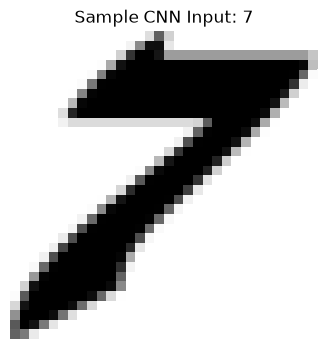

In [6]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

print("First label index:", labels[0].item())
print(
    "First character:",
    class_names[labels[0].item()]
)

plt.figure(figsize=(4, 4))

plt.imshow(
    images[0, 0].numpy(),
    cmap="gray",
    vmin=0,
    vmax=1
)

plt.title(
    f"Sample CNN Input: "
    f"{class_names[labels[0].item()]}"
)

plt.axis("off")
plt.show()


## 3. SimpleCNN architecture

Two convolution/pooling blocks and a 7-class fully connected classifier.

In [7]:

import torch
import torch.nn as nn

# Fix random seed for reproducibility
torch.manual_seed(42)

# Use CPU for the current installation
device = torch.device("cpu")

class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Feature extraction
        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Character classification
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, 7)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = SimpleCNN().to(device)

print(cnn_model)
print("Device:", device)
print("CNN model created successfully!")


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=7, bias=True)
  )
)
Device: cpu
CNN model created successfully!


In [8]:

# Get one batch
images, labels = next(iter(train_loader))

# Forward pass without training
cnn_model.eval()

with torch.no_grad():
    outputs = cnn_model(images.to(device))

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (32, 7)

print("CNN forward pass PASSED!")


Input shape: torch.Size([32, 1, 32, 32])
Output shape: torch.Size([32, 7])
CNN forward pass PASSED!


## 4. Baseline CNN training

10 epochs, Adam, LR=0.001, batch size 32. Checkpoint selection uses minimum validation loss.

In [9]:

import torch.optim as optim
import time
from pathlib import Path

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

EPOCHS = 10

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_loss = float("inf")

output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

best_model_path = output_dir / "cnn_best_baseline.pth"

for epoch in range(EPOCHS):

    start_time = time.perf_counter()

    # Training phase
    cnn_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation phase
    cnn_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # Record training history
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Save best model using validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            cnn_model.state_dict(),
            best_model_path
        )

    epoch_time = time.perf_counter() - start_time

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Time: {epoch_time:.1f}s",
        flush=True
    )

print("\nCNN training completed!")
print("Best model saved to:", best_model_path)


Epoch 01/10 | Train Loss: 0.5002 | Train Acc: 84.81% | Val Loss: 0.0941 | Val Acc: 97.24% | Time: 4.5s
Epoch 02/10 | Train Loss: 0.0977 | Train Acc: 96.87% | Val Loss: 0.0914 | Val Acc: 96.49% | Time: 2.4s
Epoch 03/10 | Train Loss: 0.0703 | Train Acc: 97.99% | Val Loss: 0.0557 | Val Acc: 98.37% | Time: 2.4s
Epoch 04/10 | Train Loss: 0.0508 | Train Acc: 98.50% | Val Loss: 0.0259 | Val Acc: 99.62% | Time: 2.3s
Epoch 05/10 | Train Loss: 0.0328 | Train Acc: 99.01% | Val Loss: 0.0196 | Val Acc: 99.75% | Time: 2.5s
Epoch 06/10 | Train Loss: 0.0219 | Train Acc: 99.36% | Val Loss: 0.0985 | Val Acc: 96.74% | Time: 2.5s
Epoch 07/10 | Train Loss: 0.0194 | Train Acc: 99.51% | Val Loss: 0.0340 | Val Acc: 98.25% | Time: 2.5s
Epoch 08/10 | Train Loss: 0.0094 | Train Acc: 99.76% | Val Loss: 0.0137 | Val Acc: 99.75% | Time: 2.4s
Epoch 09/10 | Train Loss: 0.0085 | Train Acc: 99.87% | Val Loss: 0.0220 | Val Acc: 99.50% | Time: 2.5s
Epoch 10/10 | Train Loss: 0.0075 | Train Acc: 99.87% | Val Loss: 0.0206 |

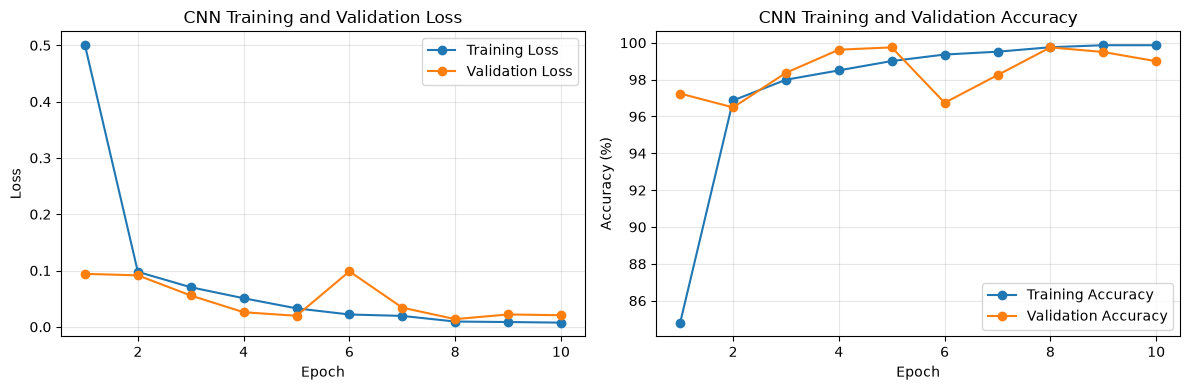

In [10]:

import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("CNN Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(
    epochs,
    np.array(history["train_acc"]) * 100,
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    epochs,
    np.array(history["val_acc"]) * 100,
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("CNN Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    output_dir / "cnn_baseline_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 5. Baseline validation and errors

Analyze classification metrics and misclassified validation characters using the saved best checkpoint.

In [11]:

import torch
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Load the best CNN checkpoint
best_model_path = MODULE_ROOT / "results/task7/cnn_best_baseline.pth"

assert best_model_path.is_file()

best_cnn = SimpleCNN().to(device)

best_cnn.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

best_cnn.eval()

print("Best CNN model loaded successfully!")


Best CNN model loaded successfully!


CNN Validation Results
Accuracy: 99.75%
Macro F1: 0.9975
Incorrect predictions: 2

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9825    0.9912       114
           4     0.9828    1.0000    0.9913       114
           7     1.0000    1.0000    1.0000       114
           8     1.0000    1.0000    1.0000       114
           A     1.0000    1.0000    1.0000       114
           D     1.0000    1.0000    1.0000       114
           H     1.0000    1.0000    1.0000       114

    accuracy                         0.9975       798
   macro avg     0.9975    0.9975    0.9975       798
weighted avg     0.9975    0.9975    0.9975       798



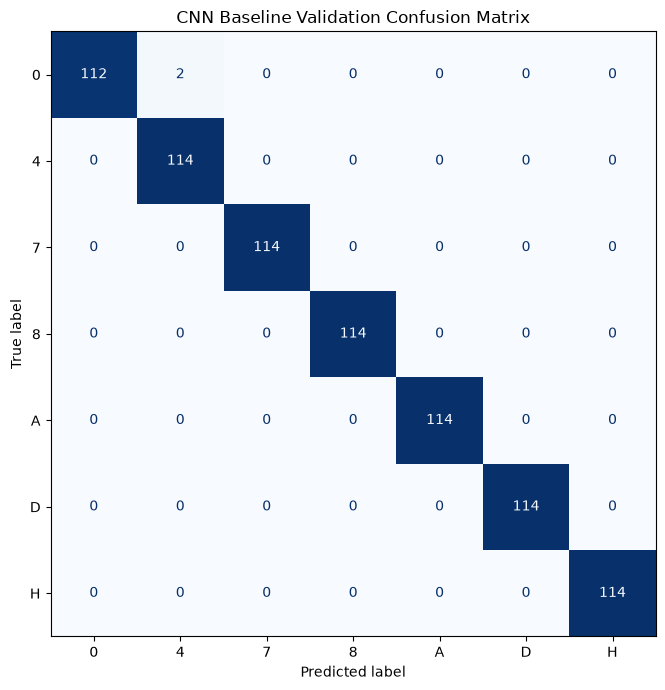

In [12]:

import time

all_predictions = []
all_labels = []

start = time.perf_counter()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = best_cnn(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_labels.extend(
            labels.tolist()
        )

val_inference_time = time.perf_counter() - start

y_true_cnn = np.array(all_labels)
y_pred_cnn = np.array(all_predictions)

cnn_val_accuracy = accuracy_score(
    y_true_cnn, y_pred_cnn
)

cnn_val_f1 = f1_score(
    y_true_cnn,
    y_pred_cnn,
    average="macro"
)

print("CNN Validation Results")
print("=" * 45)

print(f"Accuracy: {cnn_val_accuracy*100:.2f}%")
print(f"Macro F1: {cnn_val_f1:.4f}")

print(
    "Incorrect predictions:",
    np.sum(y_true_cnn != y_pred_cnn)
)

print("\nClassification Report:")

print(
    classification_report(
        y_true_cnn,
        y_pred_cnn,
        labels=list(range(7)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm_cnn = confusion_matrix(
    y_true_cnn,
    y_pred_cnn,
    labels=list(range(7))
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("CNN Baseline Validation Confusion Matrix")
plt.tight_layout()

output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "cnn_baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Incorrect CNN predictions: 2


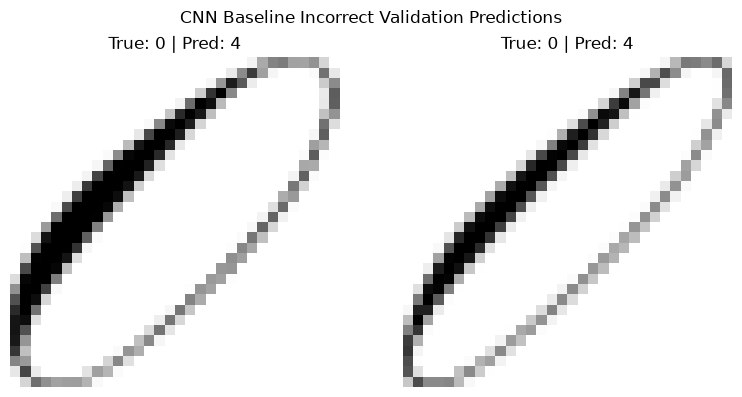

In [13]:

wrong_indices = np.where(
    y_true_cnn != y_pred_cnn
)[0]

num_errors = len(wrong_indices)

print("Incorrect CNN predictions:", num_errors)

if num_errors > 0:

    fig, axes = plt.subplots(
        1,
        num_errors,
        figsize=(4 * num_errors, 4),
        squeeze=False
    )

    for i, idx in enumerate(wrong_indices):

        record = val_records[idx]

        image = preprocess_cnn_image(
            record["path"]
        )

        true_label = class_names[y_true_cnn[idx]]
        pred_label = class_names[y_pred_cnn[idx]]

        ax = axes[0, i]

        ax.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        ax.set_title(
            f"True: {true_label} | Pred: {pred_label}"
        )

        ax.axis("off")

    plt.suptitle(
        "CNN Baseline Incorrect Validation Predictions"
    )

    plt.tight_layout()

    plt.savefig(
        output_dir / "cnn_baseline_errors.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
else:
    print("No incorrect predictions!")


## 6. Controlled learning-rate comparison

Train fresh models from fixed initialization using 0.001 vs 0.0003. This is validation-only model selection.

In [14]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
import time

from torch.utils.data import DataLoader
from pathlib import Path

output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)


def train_cnn_experiment(lr, epochs=10, seed=42):

    # 1. Fix random seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # 2. Recreate training DataLoader
    generator = torch.Generator()
    generator.manual_seed(seed)

    experiment_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    # 3. Create a NEW CNN
    model = SimpleCNN().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_val_acc = 0

    save_path = output_dir / f"cnn_lr_{lr:g}.pth"

    # 4. Training loop
    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in experiment_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size
            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += batch_size

        train_loss = running_loss / total
        train_acc = correct / total

        # 5. Validation
        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                batch_size = labels.size(0)

                val_running_loss += loss.item() * batch_size
                val_correct += (
                    outputs.argmax(1) == labels
                ).sum().item()

                val_total += batch_size

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        # 6. Record results
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Save the lowest-validation-loss checkpoint
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                save_path
            )

        print(
            f"LR={lr} | Epoch {epoch+1:02d}/{epochs} | "
            f"Train Acc={train_acc*100:.2f}% | "
            f"Val Acc={val_acc*100:.2f}% | "
            f"Val Loss={val_loss:.4f}",
            flush=True
        )

    return {
        "lr": lr,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_acc": best_val_acc,
        "model_path": save_path
    }


print("CNN training function is ready!")


CNN training function is ready!


In [15]:

learning_rates = [0.001, 0.0003]

lr_results = []

for lr in learning_rates:

    print("\n" + "=" * 60)
    print(f"Training CNN with learning rate = {lr}")
    print("=" * 60)

    result = train_cnn_experiment(
        lr=lr,
        epochs=10,
        seed=42
    )

    lr_results.append(result)

print("\nLearning rate experiments completed!")

for result in lr_results:

    print("-" * 45)
    print("Learning rate:", result["lr"])
    print("Best epoch:", result["best_epoch"])
    print(
        "Validation accuracy at selected epoch:",
        f"{result['best_val_acc']*100:.2f}%"
    )
    print(
        "Lowest validation loss:",
        f"{result['best_val_loss']:.4f}"
    )



Training CNN with learning rate = 0.001
LR=0.001 | Epoch 01/10 | Train Acc=87.61% | Val Acc=95.74% | Val Loss=0.1282
LR=0.001 | Epoch 02/10 | Train Acc=97.18% | Val Acc=97.74% | Val Loss=0.0595
LR=0.001 | Epoch 03/10 | Train Acc=98.10% | Val Acc=98.75% | Val Loss=0.0463
LR=0.001 | Epoch 04/10 | Train Acc=98.57% | Val Acc=97.74% | Val Loss=0.0564
LR=0.001 | Epoch 05/10 | Train Acc=99.03% | Val Acc=99.62% | Val Loss=0.0248
LR=0.001 | Epoch 06/10 | Train Acc=99.60% | Val Acc=99.50% | Val Loss=0.0143
LR=0.001 | Epoch 07/10 | Train Acc=99.60% | Val Acc=99.25% | Val Loss=0.0264
LR=0.001 | Epoch 08/10 | Train Acc=99.76% | Val Acc=99.75% | Val Loss=0.0103
LR=0.001 | Epoch 09/10 | Train Acc=99.76% | Val Acc=99.00% | Val Loss=0.0193
LR=0.001 | Epoch 10/10 | Train Acc=99.96% | Val Acc=99.75% | Val Loss=0.0068

Training CNN with learning rate = 0.0003
LR=0.0003 | Epoch 01/10 | Train Acc=82.50% | Val Acc=95.49% | Val Loss=0.1853
LR=0.0003 | Epoch 02/10 | Train Acc=96.25% | Val Acc=97.74% | Val Los

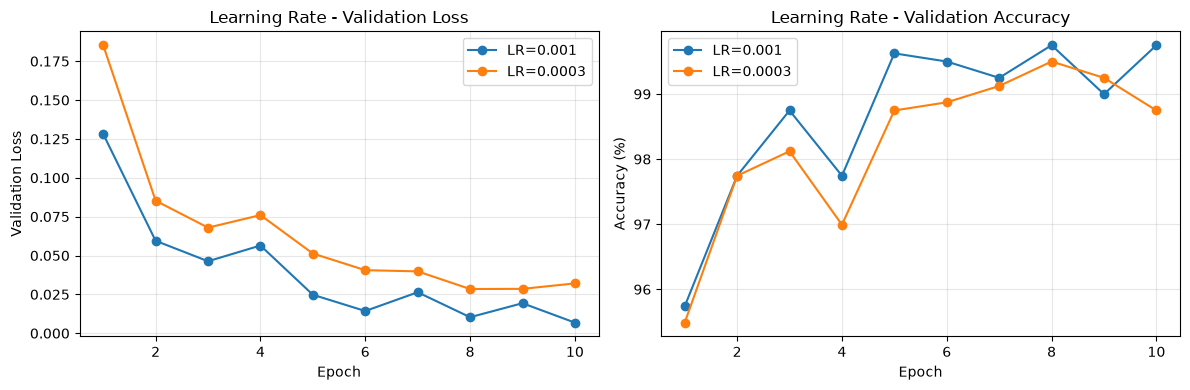

In [16]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for result in lr_results:

    lr = result["lr"]
    history_lr = result["history"]

    epochs = range(
        1,
        len(history_lr["val_loss"]) + 1
    )

    axes[0].plot(
        epochs,
        history_lr["val_loss"],
        marker="o",
        label=f"LR={lr}"
    )

    axes[1].plot(
        epochs,
        np.array(history_lr["val_acc"]) * 100,
        marker="o",
        label=f"LR={lr}"
    )

axes[0].set_title("Learning Rate - Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Learning Rate - Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    output_dir / "cnn_learning_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Final retraining on development split

Train selected configuration from scratch on train + validation = 5,334 images.

In [17]:

from torch.utils.data import DataLoader
import torch

# Combine training and validation records
dev_records = train_records + val_records

# Create the final development dataset
dev_dataset = CharacterDataset(dev_records)

# Fix the random order of training batches
generator = torch.Generator()
generator.manual_seed(42)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    generator=generator
)

print("Original training samples:", len(train_records))
print("Original validation samples:", len(val_records))
print("Final training samples:", len(dev_dataset))

assert len(dev_dataset) == 5334

print("Final CNN training dataset is ready!")


Original training samples: 4536
Original validation samples: 798
Final training samples: 5334
Final CNN training dataset is ready!


In [18]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
import time
from pathlib import Path

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Create a fresh model
final_cnn = SimpleCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    final_cnn.parameters(),
    lr=0.001
)

EPOCHS_FINAL = 10

final_train_losses = []
final_train_accs = []

start_total = time.perf_counter()

for epoch in range(EPOCHS_FINAL):

    final_cnn.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dev_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = final_cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    final_train_losses.append(epoch_loss)
    final_train_accs.append(epoch_acc)

    print(
        f"Epoch {epoch+1:02d}/10 | "
        f"Train Loss: {epoch_loss:.4f} | "
        f"Train Acc: {epoch_acc*100:.2f}%",
        flush=True
    )

final_training_time = (
    time.perf_counter() - start_total
)

# Save final model and configuration
output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

final_cnn_path = output_dir / "cnn_final_model.pth"

torch.save(
    {
        "model_state_dict": final_cnn.state_dict(),
        "class_names": class_names,
        "learning_rate": 0.001,
        "batch_size": 32,
        "epochs": EPOCHS_FINAL,
        "preprocessing": "crop_stretch",
        "training_samples": len(dev_dataset)
    },
    final_cnn_path
)

print("\nFinal CNN training completed!")
print(f"Total training time: {final_training_time:.2f} s")
print("Model saved to:", final_cnn_path)


Epoch 01/10 | Train Loss: 0.4158 | Train Acc: 87.57%
Epoch 02/10 | Train Loss: 0.0839 | Train Acc: 97.53%
Epoch 03/10 | Train Loss: 0.0556 | Train Acc: 98.26%
Epoch 04/10 | Train Loss: 0.0380 | Train Acc: 99.06%
Epoch 05/10 | Train Loss: 0.0257 | Train Acc: 99.33%
Epoch 06/10 | Train Loss: 0.0165 | Train Acc: 99.57%
Epoch 07/10 | Train Loss: 0.0123 | Train Acc: 99.63%
Epoch 08/10 | Train Loss: 0.0078 | Train Acc: 99.79%
Epoch 09/10 | Train Loss: 0.0028 | Train Acc: 99.96%
Epoch 10/10 | Train Loss: 0.0017 | Train Acc: 100.00%

Final CNN training completed!
Total training time: 23.53 s
Model saved to: results\task7\cnn_final_model.pth


## 8. Independent test evaluation

Use the fixed 1,778-image test partition after model selection.

In [19]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Create independent test dataset
test_dataset = CharacterDataset(test_records)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

final_cnn.eval()

test_true = []
test_pred = []

start = time.perf_counter()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = final_cnn(images)
        predictions = outputs.argmax(dim=1)

        test_true.extend(labels.tolist())
        test_pred.extend(predictions.cpu().tolist())

evaluation_time = time.perf_counter() - start

test_true = np.array(test_true)
test_pred = np.array(test_pred)

cnn_test_accuracy = accuracy_score(
    test_true, test_pred
)

cnn_test_f1 = f1_score(
    test_true,
    test_pred,
    average="macro"
)

cnn_test_errors = int(
    np.sum(test_true != test_pred)
)

print("=" * 55)
print("FINAL CNN TEST RESULTS")
print("=" * 55)

print("Model: SimpleCNN (2 Conv Layers)")
print("Learning Rate: 0.001")
print("Epochs: 10")
print("Training Samples: 5334")
print("Test Samples:", len(test_true))

print(f"\nTest Accuracy: {cnn_test_accuracy*100:.2f}%")
print(f"Macro F1-score: {cnn_test_f1:.4f}")
print("Correct predictions:", len(test_true) - cnn_test_errors)
print("Incorrect predictions:", cnn_test_errors)

print(
    f"Test evaluation time: {evaluation_time:.3f} s"
)

print("\nClassification Report:")

print(
    classification_report(
        test_true,
        test_pred,
        labels=list(range(7)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


FINAL CNN TEST RESULTS
Model: SimpleCNN (2 Conv Layers)
Learning Rate: 0.001
Epochs: 10
Training Samples: 5334
Test Samples: 1778

Test Accuracy: 99.16%
Macro F1-score: 0.9916
Correct predictions: 1763
Incorrect predictions: 15
Test evaluation time: 1.236 s

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       254
           4     1.0000    1.0000    1.0000       254
           7     0.9883    1.0000    0.9941       254
           8     1.0000    0.9882    0.9941       254
           A     0.9585    1.0000    0.9788       254
           D     0.9961    0.9961    0.9961       254
           H     1.0000    0.9567    0.9779       254

    accuracy                         0.9916      1778
   macro avg     0.9918    0.9916    0.9916      1778
weighted avg     0.9918    0.9916    0.9916      1778



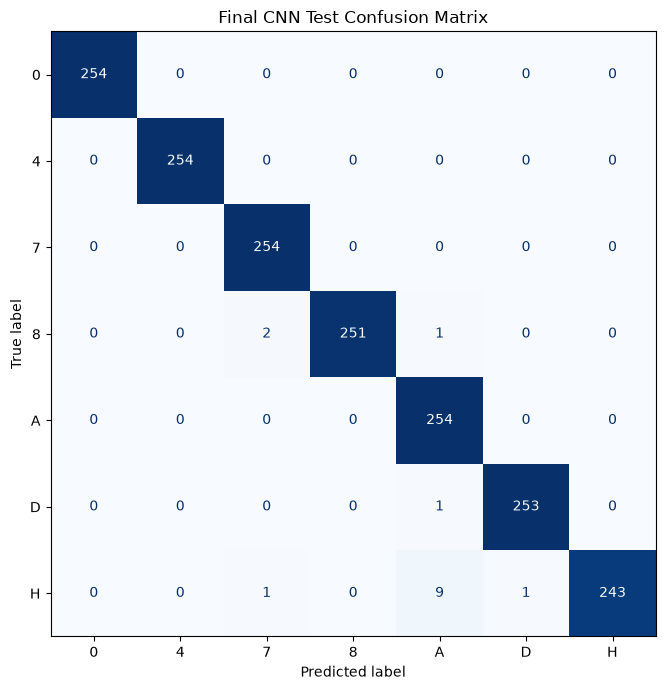

In [20]:

cm = confusion_matrix(
    test_true,
    test_pred,
    labels=list(range(7))
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final CNN Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    output_dir / "cnn_final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Real chip inference (two Task 6 pipelines)

Evaluate the saved final CNN against the same two sets of ten chip-character crops.

In [21]:

import torch
import cv2
import numpy as np
from pathlib import Path

# Load the saved final CNN
checkpoint_path = MODULE_ROOT / "results/task7/cnn_final_model.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

assert checkpoint["class_names"] == class_names

chip_cnn = SimpleCNN().to(device)

chip_cnn.load_state_dict(
    checkpoint["model_state_dict"]
)

chip_cnn.eval()

print("Final CNN loaded successfully!")

# Two Task 6 output folders
own_folder = MODULE_ROOT / "results/task6_characters_cleaned"
teammate_folder = MODULE_ROOT / "results/task6_teammate_characters"

own_paths = [
    own_folder / f"character_{i:02d}.png"
    for i in range(1, 11)
]

teammate_paths = [
    teammate_folder / f"character_{i:02d}.png"
    for i in range(1, 11)
]

assert all(p.is_file() for p in own_paths)
assert all(p.is_file() for p in teammate_paths)

print("Both Task 6 datasets are ready!")


Final CNN loaded successfully!
Both Task 6 datasets are ready!


In [22]:

def preprocess_chip_for_cnn(image_path):

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(image_path)

    # Task 6 images: white text on black background
    # Convert to black text on white background
    image = cv2.bitwise_not(image)

    # Same crop rule as CNN training
    mask = image < 245

    ys, xs = np.where(mask)

    if len(xs) > 0:
        x1 = xs.min()
        x2 = xs.max() + 1
        y1 = ys.min()
        y2 = ys.max() + 1

        image = image[y1:y2, x1:x2]

    # Same resizing method as CNN training
    image = cv2.resize(
        image,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    # Normalize to [0, 1]
    image = image.astype(np.float32) / 255.0

    return image


own_images = np.stack([
    preprocess_chip_for_cnn(p)
    for p in own_paths
])

teammate_images = np.stack([
    preprocess_chip_for_cnn(p)
    for p in teammate_paths
])

print("Your Task 6 images:", own_images.shape)
print("Teammate Task 6 images:", teammate_images.shape)


Your Task 6 images: (10, 32, 32)
Teammate Task 6 images: (10, 32, 32)


In [23]:

def predict_chip_with_cnn(images):

    # Convert NumPy array to PyTorch Tensor
    X = torch.from_numpy(
        images
    ).unsqueeze(1).to(device)

    # X shape: (10, 1, 32, 32)

    chip_cnn.eval()

    with torch.no_grad():

        outputs = chip_cnn(X)
        predicted_indices = outputs.argmax(dim=1)

    predicted_indices = predicted_indices.cpu().tolist()

    predictions = [
        class_names[idx]
        for idx in predicted_indices
    ]

    return predictions


own_cnn_predictions = predict_chip_with_cnn(
    own_images
)

teammate_cnn_predictions = predict_chip_with_cnn(
    teammate_images
)

reference_text = "HD44780A00"

own_cnn_text = "".join(own_cnn_predictions)
teammate_cnn_text = "".join(teammate_cnn_predictions)

own_correct = sum(
    p == t for p, t in zip(own_cnn_predictions, reference_text)
)

teammate_correct = sum(
    p == t for p, t in zip(teammate_cnn_predictions, reference_text)
)

print("=" * 50)
print("FINAL CNN CHIP RECOGNITION RESULTS")
print("=" * 50)

print("Reference:          ", reference_text)
print("Your Task 6:        ", own_cnn_text)
print("Teammate Task 6:    ", teammate_cnn_text)

print(
    f"\nYour Task 6 Accuracy: {own_correct}/10 "
    f"= {own_correct*10:.2f}%"
)

print(
    f"Teammate Task 6 Accuracy: {teammate_correct}/10 "
    f"= {teammate_correct*10:.2f}%"
)


FINAL CNN CHIP RECOGNITION RESULTS
Reference:           HD44780A00
Your Task 6:         H044780A00
Teammate Task 6:     HD44780A00

Your Task 6 Accuracy: 9/10 = 90.00%
Teammate Task 6 Accuracy: 10/10 = 100.00%


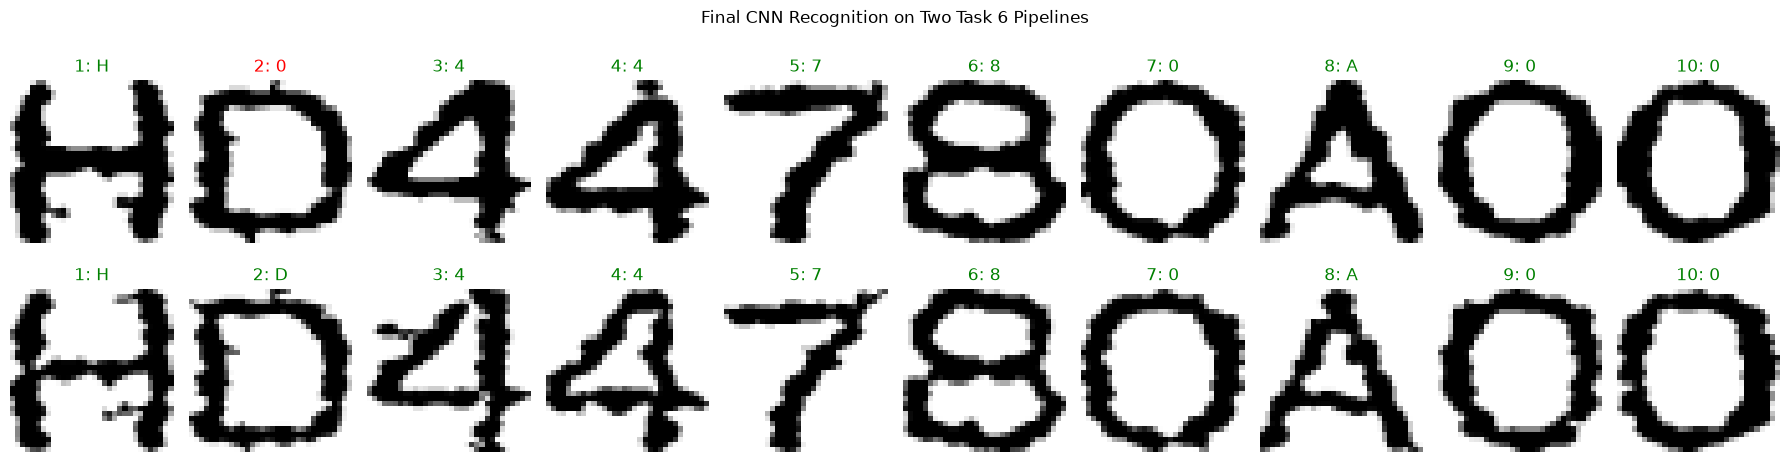

In [24]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 10,
    figsize=(18, 5)
)

datasets = [
    ("Your Task 6", own_images, own_cnn_predictions),
    ("Teammate Task 6", teammate_images, teammate_cnn_predictions)
]

for row, (name, images, predictions) in enumerate(datasets):

    for i in range(10):

        ax = axes[row, i]

        ax.imshow(
            images[i],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        correct = predictions[i] == reference_text[i]

        ax.set_title(
            f"{i+1}: {predictions[i]}",
            color="green" if correct else "red"
        )

        ax.axis("off")

    axes[row, 0].set_ylabel(
        name,
        fontsize=11
    )

plt.suptitle(
    "Final CNN Recognition on Two Task 6 Pipelines"
)

plt.tight_layout()

output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "cnn_chip_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 10. Export SVM vs CNN results

Save a compact CSV comparing the four pipelines. SVM strings are copied from recorded output; verify them against the SVM notebook.

In [25]:

import csv
from pathlib import Path

reference = "HD44780A00"

# Recorded SVM predictions from previous experiments
svm_own = "HD4478DAD0"
svm_teammate = "HD44780ADD"

# CNN predictions from current notebook
cnn_own = own_cnn_text
cnn_teammate = teammate_cnn_text

results = {
    "SVM + Your Task 6": svm_own,
    "SVM + Teammate Task 6": svm_teammate,
    "CNN + Your Task 6": cnn_own,
    "CNN + Teammate Task 6": cnn_teammate
}

output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

rows = []

for name, prediction in results.items():

    assert len(prediction) == len(reference)

    correct = sum(
        p == t
        for p, t in zip(prediction, reference)
    )

    rows.append({
        "Pipeline": name,
        "Reference": reference,
        "Prediction": prediction,
        "Correct": correct,
        "Total": len(reference),
        "Accuracy (%)": round(
            correct / len(reference) * 100, 2
        )
    })

    print(
        f"{name}: {correct}/{len(reference)} "
        f"= {correct/len(reference)*100:.2f}%"
    )

save_path = output_dir / "final_svm_cnn_comparison.csv"

with open(save_path, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=rows[0].keys()
    )

    writer.writeheader()
    writer.writerows(rows)

print("\nComparison saved to:", save_path)


SVM + Your Task 6: 8/10 = 80.00%
SVM + Teammate Task 6: 8/10 = 80.00%
CNN + Your Task 6: 9/10 = 90.00%
CNN + Teammate Task 6: 10/10 = 100.00%

Comparison saved to: results\task7\final_svm_cnn_comparison.csv
